In [ ]:
 # ==========================================
# TUGAS 05 - ADVANCED CNN & TRANSFER LEARNING
# Nama: Kenji Lawrence
# ==========================================

import torch
import torchvision
import numpy as np
import random
import matplotlib.pyplot as plt

from torchvision import datasets, transforms, models
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
from collections import Counter

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("GPU:", torch.cuda.is_available())
print("Device:", device)

if torch.cuda.is_available():
    print("GPU Name:", torch.cuda.get_device_name(0))

PyTorch: 2.11.0+cu130
Torchvision: 0.26.0+cu130
GPU: True
Device: cuda
GPU Name: Tesla T4


In [ ]:
# ==========================================
# DOWNLOAD DATASET
# ==========================================

from torchvision.datasets import OxfordIIITPet

DATA_DIR = "/content/oxford_pet"

pet_dataset = OxfordIIITPet(
    root=DATA_DIR,
    split="trainval",
    target_types="category",
    download=True
)

print("Dataset berhasil dimuat!")
print("Jumlah gambar:", len(pet_dataset))
print("Jumlah kelas:", len(pet_dataset.classes))

print("\nDaftar kelas:")

for i, name in enumerate(pet_dataset.classes):
    print(f"{i}: {name}")

Dataset berhasil dimuat!
Jumlah gambar: 3680
Jumlah kelas: 37

Daftar kelas:
0: Abyssinian
1: American Bulldog
2: American Pit Bull Terrier
3: Basset Hound
4: Beagle
5: Bengal
6: Birman
7: Bombay
8: Boxer
9: British Shorthair
10: Chihuahua
11: Egyptian Mau
12: English Cocker Spaniel
13: English Setter
14: German Shorthaired
15: Great Pyrenees
16: Havanese
17: Japanese Chin
18: Keeshond
19: Leonberger
20: Maine Coon
21: Miniature Pinscher
22: Newfoundland
23: Persian
24: Pomeranian
25: Pug
26: Ragdoll
27: Russian Blue
28: Saint Bernard
29: Samoyed
30: Scottish Terrier
31: Shiba Inu
32: Siamese
33: Sphynx
34: Staffordshire Bull Terrier
35: Wheaten Terrier
36: Yorkshire Terrier


In [ ]:
# ==========================================
# SELECT 10 CLASSES
# ==========================================

selected_classes = [
    "Abyssinian",
    "Bengal",
    "Birman",
    "Bombay",
    "Persian",
    "American Bulldog",
    "Beagle",
    "Boxer",
    "Chihuahua",
    "Pug"
]

class_to_new_idx = {
    name: idx
    for idx, name in enumerate(selected_classes)
}

selected_old_labels = [
    pet_dataset.class_to_idx[name]
    for name in selected_classes
]

all_labels = np.array(pet_dataset._labels)

selected_indices = np.where(
    np.isin(all_labels, selected_old_labels)
)[0]

print("Jumlah kelas:", len(selected_classes))
print("Total gambar:", len(selected_indices))

print("\nKelas terpilih:")

for i, name in enumerate(selected_classes):
    print(f"{i}: {name}")

Jumlah kelas: 10
Total gambar: 996

Kelas terpilih:
0: Abyssinian
1: Bengal
2: Birman
3: Bombay
4: Persian
5: American Bulldog
6: Beagle
7: Boxer
8: Chihuahua
9: Pug


In [ ]:
# ==========================================
# STRATIFIED DATA SPLIT
# ==========================================

selected_labels = all_labels[selected_indices]

train_idx, temp_idx = train_test_split(
    selected_indices,
    test_size=0.30,
    random_state=SEED,
    stratify=selected_labels
)

val_idx, test_idx = train_test_split(
    temp_idx,
    test_size=0.50,
    random_state=SEED,
    stratify=all_labels[temp_idx]
)

print("Training:", len(train_idx))
print("Validation:", len(val_idx))
print("Testing:", len(test_idx))

# Check data leakage
assert set(train_idx).isdisjoint(val_idx)
assert set(train_idx).isdisjoint(test_idx)
assert set(val_idx).isdisjoint(test_idx)

print("\nData Leakage Check: PASS")

Training: 697
Validation: 149
Testing: 150

Data Leakage Check: PASS


In [ ]:
# ==========================================
# IMAGE PREPROCESSING
# ==========================================

weights = models.ResNet18_Weights.IMAGENET1K_V1

train_transform = transforms.Compose([
    transforms.Resize(256),
    transforms.RandomResizedCrop(224, scale=(0.8, 1.0)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(15),
    transforms.ColorJitter(
        brightness=0.2,
        contrast=0.2
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

eval_transform = weights.transforms()

print("Transformasi berhasil dibuat!")

Transformasi berhasil dibuat!


In [ ]:
# ==========================================
# DATASET AND DATALOADER
# ==========================================

class PetSubset(Dataset):

    def __init__(self, base_dataset, indices):
        self.base_dataset = base_dataset
        self.indices = list(indices)

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, idx):

        image, old_label = self.base_dataset[
            self.indices[idx]
        ]

        class_name = self.base_dataset.classes[old_label]

        new_label = class_to_new_idx[class_name]

        return image, new_label


train_base = OxfordIIITPet(
    root=DATA_DIR,
    split="trainval",
    target_types="category",
    transform=train_transform,
    download=False
)

eval_base = OxfordIIITPet(
    root=DATA_DIR,
    split="trainval",
    target_types="category",
    transform=eval_transform,
    download=False
)

train_dataset = PetSubset(train_base, train_idx)
val_dataset = PetSubset(eval_base, val_idx)
test_dataset = PetSubset(eval_base, test_idx)

train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True,
    num_workers=2
)

val_loader = DataLoader(
    val_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=2
)

test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=2
)

images, labels = next(iter(train_loader))

print("Image shape:", images.shape)
print("Label shape:", labels.shape)

print("\nDataLoader berhasil!")

Image shape: torch.Size([32, 3, 224, 224])
Label shape: torch.Size([32])

DataLoader berhasil!


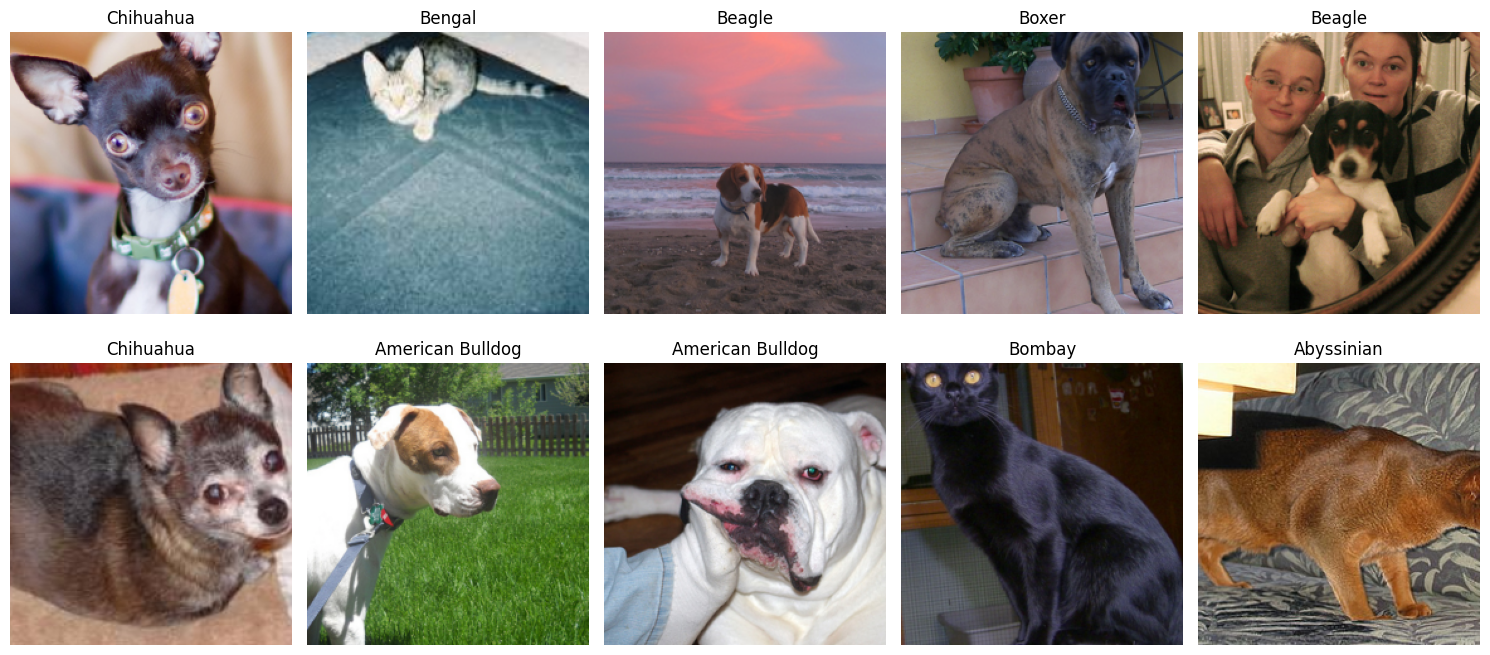

Visualisasi berhasil!


In [ ]:
# ==========================================
# DATASET VISUALIZATION
# ==========================================

import matplotlib.pyplot as plt

mean = torch.tensor(
    [0.485, 0.456, 0.406]
).view(3, 1, 1)

std = torch.tensor(
    [0.229, 0.224, 0.225]
).view(3, 1, 1)

fig, axes = plt.subplots(
    2, 5,
    figsize=(15, 7)
)

for i, ax in enumerate(axes.flat):

    image, label = test_dataset[i]

    # Reverse normalization
    image = image * std + mean

    image = image.clamp(0, 1)

    image = image.permute(
        1, 2, 0
    ).numpy()

    ax.imshow(image)

    ax.set_title(
        selected_classes[label]
    )

    ax.axis("off")

plt.tight_layout()
plt.show()

print("Visualisasi berhasil!")

In [ ]:

# ==========================================
# TRAINING UTILITIES FOR B1-B4
# ==========================================

import copy
import time
import pandas as pd
import torch.nn as nn

from sklearn.metrics import accuracy_score, f1_score

EPOCHS = 15
PATIENCE = 3

criterion = nn.CrossEntropyLoss()


def evaluate_loss(model, loader):
    model.eval()
    total_loss = 0.0
    total_samples = 0

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            total_loss += loss.item() * labels.size(0)
            total_samples += labels.size(0)

    return total_loss / total_samples


def train_model(model, optimizer, train_loader, val_loader,
                experiment_name, max_epochs=EPOCHS,
                patience=PATIENCE):

    model = model.to(device)

    history = {
        "train_loss": [],
        "val_loss": [],
        "val_accuracy": []
    }

    best_val_loss = float("inf")
    best_state = None
    best_epoch = 0
    epochs_without_improvement = 0

    start_time = time.time()

    for epoch in range(max_epochs):
        model.train()

        running_loss = 0.0
        total_samples = 0

        for images, labels in train_loader:
            images = images.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()

            outputs = model(images)
            loss = criterion(outputs, labels)

            loss.backward()
            optimizer.step()

            running_loss += loss.item() * labels.size(0)
            total_samples += labels.size(0)

        train_loss = running_loss / total_samples
        val_loss = evaluate_loss(model, val_loader)

        # Validation accuracy
        model.eval()
        correct = 0
        total = 0

        with torch.no_grad():
            for images, labels in val_loader:
                images = images.to(device)
                labels = labels.to(device)

                outputs = model(images)
                predictions = outputs.argmax(dim=1)

                correct += (predictions == labels).sum().item()
                total += labels.size(0)

        val_accuracy = correct / total

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["val_accuracy"].append(val_accuracy)

        print(
            f"{experiment_name} | "
            f"Epoch {epoch + 1:02d}/{max_epochs} | "
            f"Train Loss: {train_loss:.4f} | "
            f"Val Loss: {val_loss:.4f} | "
            f"Val Acc: {val_accuracy:.4f}"
        )

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_epoch = epoch + 1
            best_state = copy.deepcopy({
                k: v.detach().cpu()
                for k, v in model.state_dict().items()
            })
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1

        if epochs_without_improvement >= patience:
            print("Early stopping triggered.")
            break

    duration = time.time() - start_time

    if best_state is not None:
        model.load_state_dict(best_state)

    print(f"\nBest epoch: {best_epoch}")
    print(f"Training time: {duration:.2f} seconds")

    return model, history, {
        "best_epoch": best_epoch,
        "best_val_loss": best_val_loss,
        "duration_seconds": duration
    }


def count_trainable_parameters(model):
    return sum(
        p.numel()
        for p in model.parameters()
        if p.requires_grad
    )


print("Training utilities siap digunakan.")


Training utilities siap digunakan.


In [ ]:

# ==========================================
# B1: RESNET-18 FROM SCRATCH
# ==========================================

model_b1 = models.resnet18(weights=None)

# Ganti classifier menjadi 10 kelas
model_b1.fc = nn.Linear(
    model_b1.fc.in_features,
    len(selected_classes)
)

print("Trainable parameters B1:",
      f"{count_trainable_parameters(model_b1):,}")

optimizer_b1 = torch.optim.AdamW(
    model_b1.parameters(),
    lr=1e-3,
    weight_decay=1e-2
)

model_b1, history_b1, result_b1 = train_model(
    model=model_b1,
    optimizer=optimizer_b1,
    train_loader=train_loader,
    val_loader=val_loader,
    experiment_name="B1 - From Scratch"
)

print("\nB1 selesai.")


Trainable parameters B1: 11,181,642
B1 - From Scratch | Epoch 01/15 | Train Loss: 2.3562 | Val Loss: 4.9599 | Val Acc: 0.1879
B1 - From Scratch | Epoch 02/15 | Train Loss: 2.0901 | Val Loss: 2.4126 | Val Acc: 0.2416
B1 - From Scratch | Epoch 03/15 | Train Loss: 1.9143 | Val Loss: 2.3224 | Val Acc: 0.2685
B1 - From Scratch | Epoch 04/15 | Train Loss: 1.8301 | Val Loss: 2.3079 | Val Acc: 0.2886
B1 - From Scratch | Epoch 05/15 | Train Loss: 1.7374 | Val Loss: 2.1455 | Val Acc: 0.3289
B1 - From Scratch | Epoch 06/15 | Train Loss: 1.7424 | Val Loss: 2.2895 | Val Acc: 0.3087
B1 - From Scratch | Epoch 07/15 | Train Loss: 1.6428 | Val Loss: 2.0386 | Val Acc: 0.3221
B1 - From Scratch | Epoch 08/15 | Train Loss: 1.6218 | Val Loss: 1.9576 | Val Acc: 0.3691
B1 - From Scratch | Epoch 09/15 | Train Loss: 1.4664 | Val Loss: 2.0443 | Val Acc: 0.3356
B1 - From Scratch | Epoch 10/15 | Train Loss: 1.5016 | Val Loss: 2.1763 | Val Acc: 0.3624
B1 - From Scratch | Epoch 11/15 | Train Loss: 1.4286 | Val Loss:

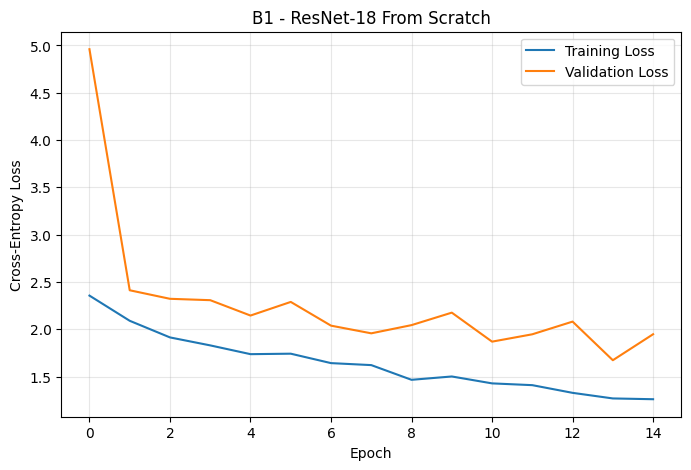

In [ ]:

# ==========================================
# B1: LOSS CURVE
# ==========================================

plt.figure(figsize=(8, 5))

plt.plot(
    history_b1["train_loss"],
    label="Training Loss"
)

plt.plot(
    history_b1["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Cross-Entropy Loss")
plt.title("B1 - ResNet-18 From Scratch")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


In [ ]:

# ==========================================
# B2: FEATURE EXTRACTION
# ==========================================

# Load pretrained ResNet-18
model_b2 = models.resnet18(
    weights=models.ResNet18_Weights.IMAGENET1K_V1
)

# Freeze seluruh parameter backbone
for param in model_b2.parameters():
    param.requires_grad = False

# Ganti classifier untuk 10 kelas
model_b2.fc = nn.Linear(
    model_b2.fc.in_features,
    len(selected_classes)
)

# Pastikan hanya classifier yang dilatih
print(
    "Trainable parameters B2:",
    f"{count_trainable_parameters(model_b2):,}"
)

# Optimizer hanya untuk classifier
optimizer_b2 = torch.optim.AdamW(
    model_b2.fc.parameters(),
    lr=1e-3,
    weight_decay=1e-2
)

# Train
model_b2, history_b2, result_b2 = train_model(
    model=model_b2,
    optimizer=optimizer_b2,
    train_loader=train_loader,
    val_loader=val_loader,
    experiment_name="B2 - Feature Extraction"
)

print("\nB2 selesai.")


Trainable parameters B2: 5,130
B2 - Feature Extraction | Epoch 01/15 | Train Loss: 1.7586 | Val Loss: 1.1378 | Val Acc: 0.8121
B2 - Feature Extraction | Epoch 02/15 | Train Loss: 0.9483 | Val Loss: 0.7283 | Val Acc: 0.8523
B2 - Feature Extraction | Epoch 03/15 | Train Loss: 0.6379 | Val Loss: 0.5150 | Val Acc: 0.8859
B2 - Feature Extraction | Epoch 04/15 | Train Loss: 0.5056 | Val Loss: 0.4445 | Val Acc: 0.8926
B2 - Feature Extraction | Epoch 05/15 | Train Loss: 0.3885 | Val Loss: 0.3895 | Val Acc: 0.9195
B2 - Feature Extraction | Epoch 06/15 | Train Loss: 0.3239 | Val Loss: 0.3565 | Val Acc: 0.9060
B2 - Feature Extraction | Epoch 07/15 | Train Loss: 0.2958 | Val Loss: 0.3399 | Val Acc: 0.9060
B2 - Feature Extraction | Epoch 08/15 | Train Loss: 0.2609 | Val Loss: 0.3070 | Val Acc: 0.9262
B2 - Feature Extraction | Epoch 09/15 | Train Loss: 0.2449 | Val Loss: 0.2977 | Val Acc: 0.9329
B2 - Feature Extraction | Epoch 10/15 | Train Loss: 0.2201 | Val Loss: 0.2959 | Val Acc: 0.9128
B2 - Feat

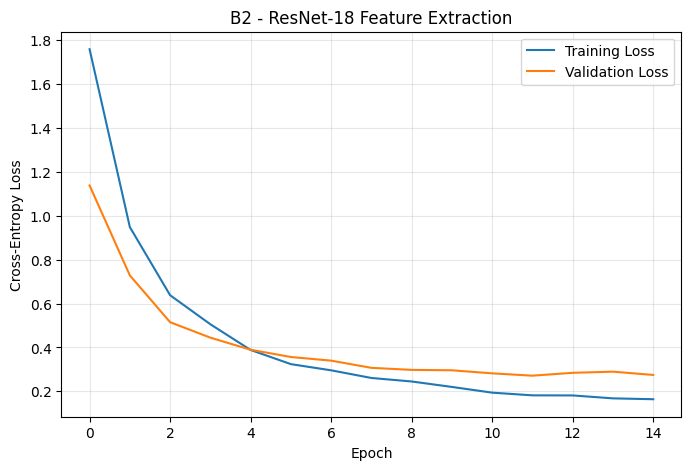

In [ ]:

plt.figure(figsize=(8, 5))

plt.plot(
    history_b2["train_loss"],
    label="Training Loss"
)

plt.plot(
    history_b2["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Cross-Entropy Loss")
plt.title("B2 - ResNet-18 Feature Extraction")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


In [ ]:

comparison = pd.DataFrame([
    {
        "Experiment": "B1 - From Scratch",
        "Trainable Parameters": count_trainable_parameters(model_b1),
        "Best Epoch": result_b1["best_epoch"],
        "Best Validation Loss": result_b1["best_val_loss"],
        "Duration (seconds)": result_b1["duration_seconds"],
        "Final Validation Accuracy": history_b1["val_accuracy"][-1]
    },
    {
        "Experiment": "B2 - Feature Extraction",
        "Trainable Parameters": count_trainable_parameters(model_b2),
        "Best Epoch": result_b2["best_epoch"],
        "Best Validation Loss": result_b2["best_val_loss"],
        "Duration (seconds)": result_b2["duration_seconds"],
        "Final Validation Accuracy": history_b2["val_accuracy"][-1]
    }
])

display(comparison.round(4))


,Experiment,Trainable Parameters,Best Epoch,Best Validation Loss,Duration (seconds),Final Validation Accuracy
0,B1 - From Scratch,11181642,14,1.6733,135.5376,0.4228
1,B2 - Feature Extraction,5130,12,0.2714,118.4369,0.9195


In [ ]:

# ==========================================
# B3: PROGRESSIVE FINE-TUNING
# ==========================================

# Mulai dari pretrained ResNet-18 yang baru
model_b3 = models.resnet18(
    weights=models.ResNet18_Weights.IMAGENET1K_V1
)

# Bekukan seluruh backbone terlebih dahulu
for param in model_b3.parameters():
    param.requires_grad = False

# Buka layer4
for param in model_b3.layer4.parameters():
    param.requires_grad = True

# Ganti classifier untuk 10 kelas
model_b3.fc = nn.Linear(
    model_b3.fc.in_features,
    len(selected_classes)
)

# Verifikasi parameter
print(
    "Trainable parameters B3:",
    f"{count_trainable_parameters(model_b3):,}"
)

# Differential learning rate
optimizer_b3 = torch.optim.AdamW(
    [
        {
            "params": model_b3.layer4.parameters(),
            "lr": 1e-4
        },
        {
            "params": model_b3.fc.parameters(),
            "lr": 1e-3
        }
    ],
    weight_decay=1e-2
)

# Training
model_b3, history_b3, result_b3 = train_model(
    model=model_b3,
    optimizer=optimizer_b3,
    train_loader=train_loader,
    val_loader=val_loader,
    experiment_name="B3 - Progressive Fine-Tuning"
)

print("\nB3 selesai.")


Trainable parameters B3: 8,398,858
B3 - Progressive Fine-Tuning | Epoch 01/15 | Train Loss: 1.1586 | Val Loss: 0.2844 | Val Acc: 0.9329
B3 - Progressive Fine-Tuning | Epoch 02/15 | Train Loss: 0.2344 | Val Loss: 0.2384 | Val Acc: 0.9329
B3 - Progressive Fine-Tuning | Epoch 03/15 | Train Loss: 0.1177 | Val Loss: 0.2487 | Val Acc: 0.9329
B3 - Progressive Fine-Tuning | Epoch 04/15 | Train Loss: 0.0780 | Val Loss: 0.2428 | Val Acc: 0.9262
B3 - Progressive Fine-Tuning | Epoch 05/15 | Train Loss: 0.0460 | Val Loss: 0.2568 | Val Acc: 0.9262
Early stopping triggered.

Best epoch: 2
Training time: 40.56 seconds

B3 selesai.


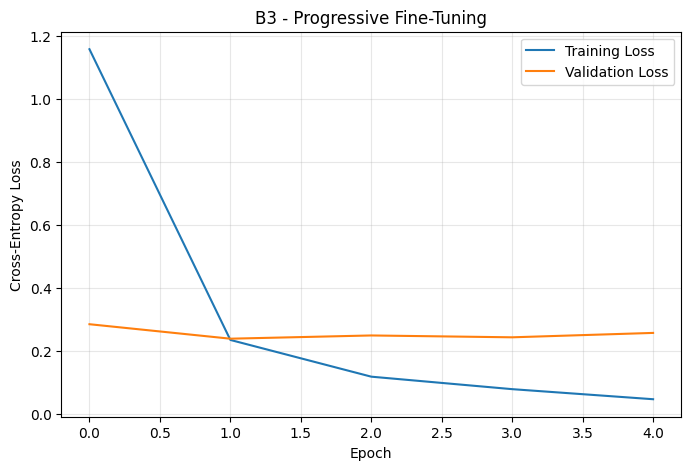

In [ ]:

plt.figure(figsize=(8, 5))

plt.plot(
    history_b3["train_loss"],
    label="Training Loss"
)

plt.plot(
    history_b3["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Cross-Entropy Loss")
plt.title("B3 - Progressive Fine-Tuning")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


In [ ]:

comparison_b1_b3 = pd.DataFrame([
    {
        "Experiment": "B1 - From Scratch",
        "Trainable Parameters": count_trainable_parameters(model_b1),
        "Best Epoch": result_b1["best_epoch"],
        "Best Validation Loss": result_b1["best_val_loss"],
        "Duration (s)": result_b1["duration_seconds"]
    },
    {
        "Experiment": "B2 - Feature Extraction",
        "Trainable Parameters": count_trainable_parameters(model_b2),
        "Best Epoch": result_b2["best_epoch"],
        "Best Validation Loss": result_b2["best_val_loss"],
        "Duration (s)": result_b2["duration_seconds"]
    },
    {
        "Experiment": "B3 - Fine-Tuning",
        "Trainable Parameters": count_trainable_parameters(model_b3),
        "Best Epoch": result_b3["best_epoch"],
        "Best Validation Loss": result_b3["best_val_loss"],
        "Duration (s)": result_b3["duration_seconds"]
    }
])

display(comparison_b1_b3.round(4))


,Experiment,Trainable Parameters,Best Epoch,Best Validation Loss,Duration (s)
0,B1 - From Scratch,11181642,14,1.6733,135.5376
1,B2 - Feature Extraction,5130,12,0.2714,118.4369
2,B3 - Fine-Tuning,8398858,2,0.2384,40.5579


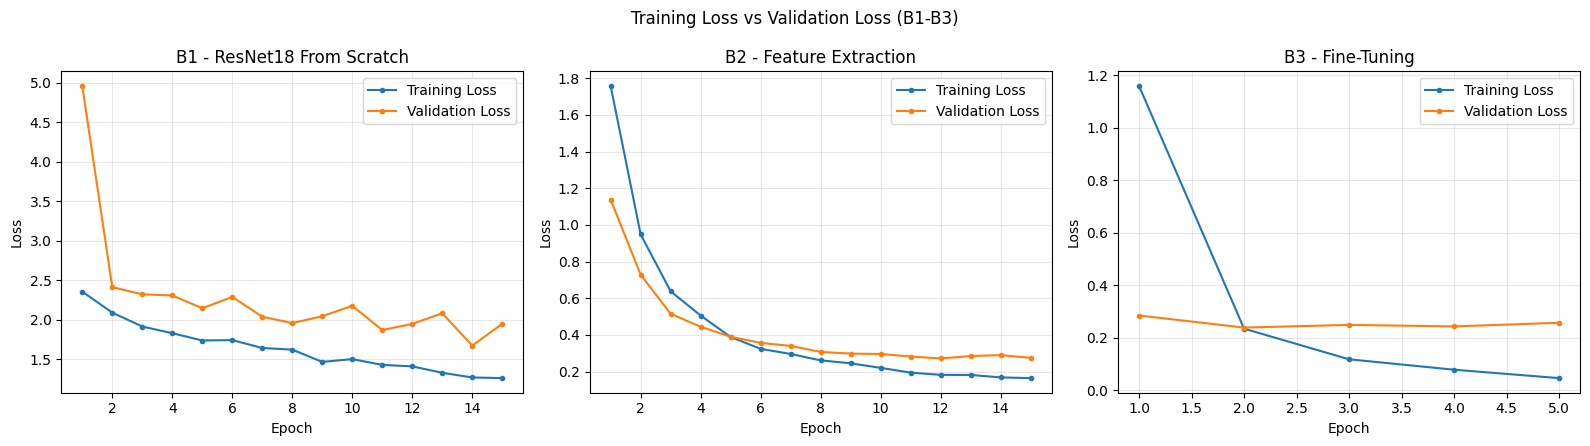

In [63]:

# ==========================================
# KURVA TRAINING LOSS DAN VALIDATION LOSS B1-B3
# ==========================================

import matplotlib.pyplot as plt

experiments = {
    "B1 - ResNet18 From Scratch": history_b1,
    "B2 - Feature Extraction": history_b2,
    "B3 - Fine-Tuning": history_b3
}

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

for ax, (name, history) in zip(axes, experiments.items()):
    train_loss = history["train_loss"]
    val_loss = history["val_loss"]

    epochs = range(1, len(train_loss) + 1)

    ax.plot(
        epochs, train_loss,
        marker="o", markersize=3,
        label="Training Loss"
    )
    ax.plot(
        epochs, val_loss,
        marker="o", markersize=3,
        label="Validation Loss"
    )

    ax.set_title(name)
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Loss")
    ax.legend()
    ax.grid(True, alpha=0.3)

plt.suptitle("Training Loss vs Validation Loss (B1-B3)")
plt.tight_layout()

plt.savefig(
    "kurva_loss_B1_B3.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [ ]:

# ==========================================
# B4: CONTROL WITHOUT AUGMENTATION
# ==========================================

# Gunakan transformasi deterministik yang sama seperti evaluasi
train_no_aug_base = OxfordIIITPet(
    root=DATA_DIR,
    split="trainval",
    target_types="category",
    transform=eval_transform,
    download=False
)

train_no_aug_dataset = PetSubset(
    train_no_aug_base,
    train_idx
)

train_no_aug_loader = DataLoader(
    train_no_aug_dataset,
    batch_size=32,
    shuffle=True,
    num_workers=2
)

print("Training samples:", len(train_no_aug_dataset))
print("Augmentation: OFF")
print("Validation samples:", len(val_dataset))


Training samples: 697
Augmentation: OFF
Validation samples: 149


In [ ]:

# ==========================================
# B4: FEATURE EXTRACTION WITHOUT AUGMENTATION
# ==========================================

model_b4_no_aug = models.resnet18(
    weights=models.ResNet18_Weights.IMAGENET1K_V1
)

for param in model_b4_no_aug.parameters():
    param.requires_grad = False

model_b4_no_aug.fc = nn.Linear(
    model_b4_no_aug.fc.in_features,
    len(selected_classes)
)

optimizer_b4_no_aug = torch.optim.AdamW(
    model_b4_no_aug.fc.parameters(),
    lr=1e-3,
    weight_decay=1e-2
)

model_b4_no_aug, history_b4_no_aug, result_b4_no_aug = train_model(
    model=model_b4_no_aug,
    optimizer=optimizer_b4_no_aug,
    train_loader=train_no_aug_loader,
    val_loader=val_loader,
    experiment_name="B4 - No Augmentation"
)

print("B4 tanpa augmentasi selesai.")


B4 - No Augmentation | Epoch 01/15 | Train Loss: 1.9488 | Val Loss: 1.2463 | Val Acc: 0.7315
B4 - No Augmentation | Epoch 02/15 | Train Loss: 0.9251 | Val Loss: 0.7131 | Val Acc: 0.8859
B4 - No Augmentation | Epoch 03/15 | Train Loss: 0.5198 | Val Loss: 0.5219 | Val Acc: 0.8926
B4 - No Augmentation | Epoch 04/15 | Train Loss: 0.3682 | Val Loss: 0.4313 | Val Acc: 0.9128
B4 - No Augmentation | Epoch 05/15 | Train Loss: 0.2848 | Val Loss: 0.3752 | Val Acc: 0.8993
B4 - No Augmentation | Epoch 06/15 | Train Loss: 0.2410 | Val Loss: 0.3605 | Val Acc: 0.8993
B4 - No Augmentation | Epoch 07/15 | Train Loss: 0.2025 | Val Loss: 0.3293 | Val Acc: 0.9060
B4 - No Augmentation | Epoch 08/15 | Train Loss: 0.1786 | Val Loss: 0.3322 | Val Acc: 0.8993
B4 - No Augmentation | Epoch 09/15 | Train Loss: 0.1473 | Val Loss: 0.2973 | Val Acc: 0.9128
B4 - No Augmentation | Epoch 10/15 | Train Loss: 0.1415 | Val Loss: 0.2907 | Val Acc: 0.9128
B4 - No Augmentation | Epoch 11/15 | Train Loss: 0.1463 | Val Loss: 0.

,Condition,Best Epoch,Best Validation Loss,Duration (s)
0,B2 - With Augmentation,12,0.2714,118.4369
1,B4 - Without Augmentation,15,0.2633,88.9911


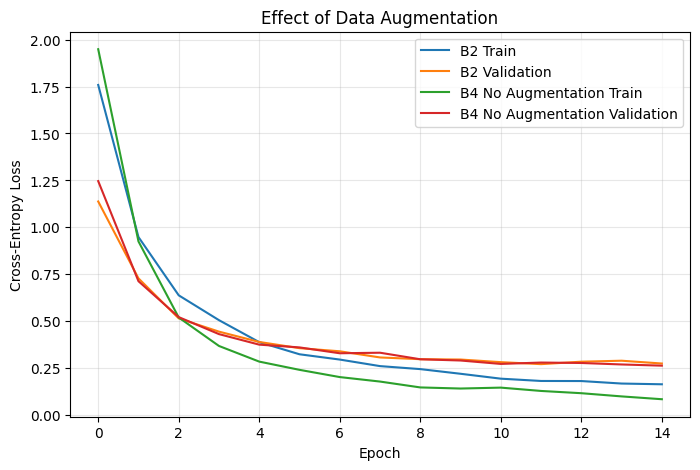

In [ ]:

# ==========================================
# AUGMENTATION COMPARISON
# ==========================================

augmentation_comparison = pd.DataFrame([
    {
        "Condition": "B2 - With Augmentation",
        "Best Epoch": result_b2["best_epoch"],
        "Best Validation Loss": result_b2["best_val_loss"],
        "Duration (s)": result_b2["duration_seconds"]
    },
    {
        "Condition": "B4 - Without Augmentation",
        "Best Epoch": result_b4_no_aug["best_epoch"],
        "Best Validation Loss": result_b4_no_aug["best_val_loss"],
        "Duration (s)": result_b4_no_aug["duration_seconds"]
    }
])

display(augmentation_comparison.round(4))

plt.figure(figsize=(8, 5))
plt.plot(history_b2["train_loss"], label="B2 Train")
plt.plot(history_b2["val_loss"], label="B2 Validation")
plt.plot(
    history_b4_no_aug["train_loss"],
    label="B4 No Augmentation Train"
)
plt.plot(
    history_b4_no_aug["val_loss"],
    label="B4 No Augmentation Validation"
)
plt.xlabel("Epoch")
plt.ylabel("Cross-Entropy Loss")
plt.title("Effect of Data Augmentation")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


In [ ]:

# ==========================================
# TEST SET EVALUATION
# ==========================================

def evaluate_test(model, loader):
    model.eval()

    y_true = []
    y_pred = []

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)

            outputs = model(images)
            predictions = outputs.argmax(dim=1).cpu().numpy()

            y_pred.extend(predictions.tolist())
            y_true.extend(labels.numpy().tolist())

    return {
        "Test Accuracy": accuracy_score(y_true, y_pred),
        "Macro F1": f1_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        )
    }


models_to_evaluate = {
    "B1 - From Scratch": model_b1,
    "B2 - Feature Extraction": model_b2,
    "B3 - Fine-Tuning": model_b3,
    "B4 - No Augmentation": model_b4_no_aug
}

test_results = []

for name, model in models_to_evaluate.items():
    metrics = evaluate_test(model, test_loader)

    test_results.append({
        "Experiment": name,
        "Test Accuracy": metrics["Test Accuracy"],
        "Macro F1": metrics["Macro F1"]
    })

    print(
        f"{name}: "
        f"Accuracy={metrics['Test Accuracy']:.4f}, "
        f"Macro F1={metrics['Macro F1']:.4f}"
    )

test_results_df = pd.DataFrame(test_results)
display(test_results_df.round(4))


B1 - From Scratch: Accuracy=0.3733, Macro F1=0.3721
B2 - Feature Extraction: Accuracy=0.9067, Macro F1=0.9061
B3 - Fine-Tuning: Accuracy=0.9200, Macro F1=0.9193
B4 - No Augmentation: Accuracy=0.9267, Macro F1=0.9262


,Experiment,Test Accuracy,Macro F1
0,B1 - From Scratch,0.3733,0.3721
1,B2 - Feature Extraction,0.9067,0.9061
2,B3 - Fine-Tuning,0.9200,0.9193
3,B4 - No Augmentation,0.9267,0.9262


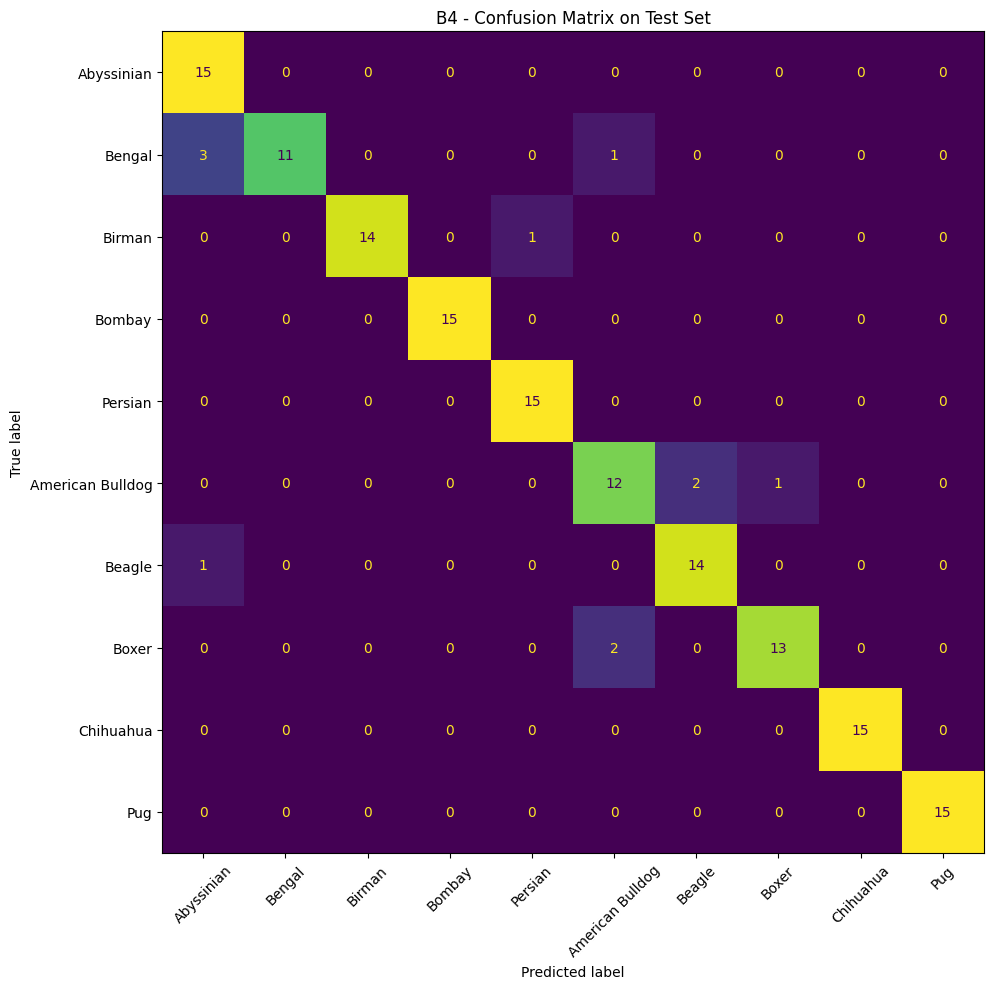

In [ ]:

# ==========================================
# CONFUSION MATRIX - B4
# ==========================================

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

def get_predictions(model, loader):
    model.eval()
    y_true, y_pred, confidences = [], [], []

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            outputs = model(images)
            probabilities = torch.softmax(outputs, dim=1)

            confidence, predictions = probabilities.max(dim=1)

            y_true.extend(labels.numpy().tolist())
            y_pred.extend(predictions.cpu().numpy().tolist())
            confidences.extend(confidence.cpu().numpy().tolist())

    return np.array(y_true), np.array(y_pred), np.array(confidences)


y_true_b4, y_pred_b4, conf_b4 = get_predictions(
    model_b4_no_aug, test_loader
)

cm = confusion_matrix(
    y_true_b4,
    y_pred_b4,
    labels=list(range(len(selected_classes)))
)

fig, ax = plt.subplots(figsize=(12, 10))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=selected_classes
)

disp.plot(
    ax=ax,
    xticks_rotation=45,
    values_format="d",
    colorbar=False
)

plt.title("B4 - Confusion Matrix on Test Set")
plt.tight_layout()
plt.show()


Jumlah salah prediksi: 11


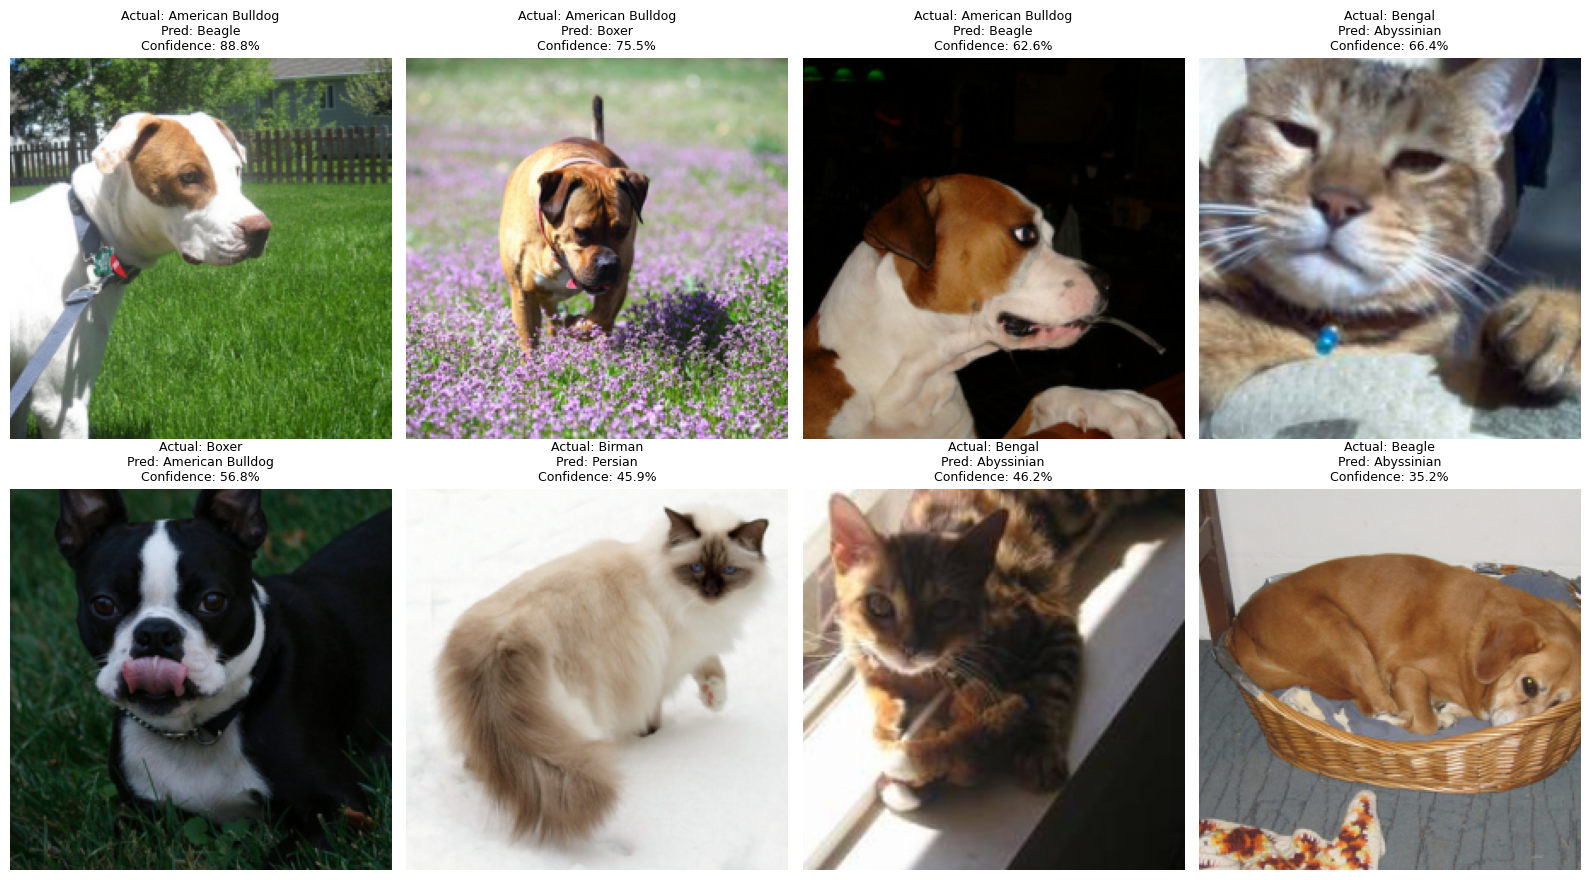

In [ ]:

# ==========================================
# FAILURE ANALYSIS - B4
# ==========================================

wrong_indices = np.where(y_true_b4 != y_pred_b4)[0]

print("Jumlah salah prediksi:", len(wrong_indices))

if len(wrong_indices) == 0:
    print("Tidak ada kesalahan prediksi pada test set.")
else:
    n_show = min(8, len(wrong_indices))

    fig, axes = plt.subplots(
        2, 4, figsize=(16, 9)
    )

    for ax, idx in zip(axes.flat, wrong_indices[:n_show]):
        image, true_label = test_dataset[int(idx)]

        mean = torch.tensor(
            [0.485, 0.456, 0.406]
        ).view(3, 1, 1)

        std = torch.tensor(
            [0.229, 0.224, 0.225]
        ).view(3, 1, 1)

        image = (image * std + mean).clamp(0, 1)
        image = image.permute(1, 2, 0).numpy()

        pred_label = int(y_pred_b4[idx])
        confidence = float(conf_b4[idx])

        ax.imshow(image)
        ax.set_title(
            f"Actual: {selected_classes[int(true_label)]}\n"
            f"Pred: {selected_classes[pred_label]}\n"
            f"Confidence: {confidence:.1%}",
            fontsize=9
        )
        ax.axis("off")

    for ax in axes.flat[n_show:]:
        ax.axis("off")

    plt.tight_layout()
    plt.show()


In [ ]:

# ==========================================
# SAVE EXPERIMENT LOGS
# ==========================================

import json
import os

experiment_configs = [
    {
        "experiment": "B1 - From Scratch",
        "model": model_b1,
        "history": history_b1,
        "result": result_b1,
        "learning_rate": "1e-3",
        "augmentation": True
    },
    {
        "experiment": "B2 - Feature Extraction",
        "model": model_b2,
        "history": history_b2,
        "result": result_b2,
        "learning_rate": "1e-3",
        "augmentation": True
    },
    {
        "experiment": "B3 - Fine-Tuning",
        "model": model_b3,
        "history": history_b3,
        "result": result_b3,
        "learning_rate": "layer4=1e-4; fc=1e-3",
        "augmentation": True
    },
    {
        "experiment": "B4 - No Augmentation",
        "model": model_b4_no_aug,
        "history": history_b4_no_aug,
        "result": result_b4_no_aug,
        "learning_rate": "1e-3",
        "augmentation": False
    }
]

os.makedirs("/content/tugas05_results", exist_ok=True)

summary_rows = []
raw_logs = []

for config in experiment_configs:
    y_true, y_pred, confidences = get_predictions(
        config["model"], test_loader
    )

    metrics = {
        "test_accuracy": float(accuracy_score(y_true, y_pred)),
        "test_macro_f1": float(f1_score(
            y_true, y_pred,
            average="macro",
            zero_division=0
        ))
    }

    row = {
        "experiment": config["experiment"],
        "trainable_parameters": count_trainable_parameters(
            config["model"]
        ),
        "learning_rate": config["learning_rate"],
        "best_epoch": config["result"]["best_epoch"],
        "duration_seconds": config["result"]["duration_seconds"],
        "best_validation_loss": config["result"]["best_val_loss"],
        "test_accuracy": metrics["test_accuracy"],
        "test_macro_f1": metrics["test_macro_f1"],
        "augmentation": config["augmentation"]
    }

    summary_rows.append(row)

    raw_logs.append({
        **row,
        "train_loss_per_epoch": config["history"]["train_loss"],
        "validation_loss_per_epoch": config["history"]["val_loss"],
        "validation_accuracy_per_epoch": config["history"]["val_accuracy"]
    })

summary_df = pd.DataFrame(summary_rows)

summary_df.to_csv(
    "/content/tugas05_results/experiment_summary.csv",
    index=False
)

with open(
    "/content/tugas05_results/experiment_logs.json",
    "w"
) as f:
    json.dump(raw_logs, f, indent=2)

print("Log berhasil disimpan:")
print("/content/tugas05_results/experiment_summary.csv")
print("/content/tugas05_results/experiment_logs.json")

display(summary_df.round(4))


Log berhasil disimpan:
/content/tugas05_results/experiment_summary.csv
/content/tugas05_results/experiment_logs.json


,experiment,trainable_parameters,learning_rate,best_epoch,duration_seconds,best_validation_loss,test_accuracy,test_macro_f1,augmentation
0,B1 - From Scratch,11181642,1e-3,14,135.5376,1.6733,0.3733,0.3721,True
1,B2 - Feature Extraction,5130,1e-3,12,118.4369,0.2714,0.9067,0.9061,True
2,B3 - Fine-Tuning,8398858,layer4=1e-4; fc=1e-3,2,40.5579,0.2384,0.9200,0.9193,True
3,B4 - No Augmentation,5130,1e-3,15,88.9911,0.2633,0.9267,0.9262,False


In [ ]:

# ==========================================
# FINAL METRICS - BEST RESTORED MODELS
# ==========================================

final_rows = []

for config in experiment_configs:
    model = config["model"]

    val_metrics = evaluate_test(model, val_loader)
    test_metrics = evaluate_test(model, test_loader)

    final_rows.append({
        "Experiment": config["experiment"],
        "Trainable Parameters": count_trainable_parameters(model),
        "Best Epoch": config["result"]["best_epoch"],
        "Best Validation Loss": config["result"]["best_val_loss"],
        "Validation Accuracy": val_metrics["Test Accuracy"],
        "Test Accuracy": test_metrics["Test Accuracy"],
        "Test Macro F1": test_metrics["Macro F1"],
        "Duration (seconds)": config["result"]["duration_seconds"],
        "Augmentation": config["augmentation"]
    })

final_df = pd.DataFrame(final_rows)

display(final_df.round(4))

final_df.to_csv(
    "/content/tugas05_results/final_metrics.csv",
    index=False
)

final_df.to_json(
    "/content/tugas05_results/final_metrics.json",
    orient="records",
    indent=2
)

print("Final metrics berhasil disimpan.")


,Experiment,Trainable Parameters,Best Epoch,Best Validation Loss,Validation Accuracy,Test Accuracy,Test Macro F1,Duration (seconds),Augmentation
0,B1 - From Scratch,11181642,14,1.6733,0.4698,0.3733,0.3721,135.5376,True
1,B2 - Feature Extraction,5130,12,0.2714,0.9262,0.9067,0.9061,118.4369,True
2,B3 - Fine-Tuning,8398858,2,0.2384,0.9329,0.9200,0.9193,40.5579,True
3,B4 - No Augmentation,5130,15,0.2633,0.9060,0.9267,0.9262,88.9911,False


Final metrics berhasil disimpan.


In [ ]:

# ==========================================
# FAILURE ANALYSIS TABLE
# ==========================================

wrong_indices = np.where(y_true_b4 != y_pred_b4)[0]
failure_rows = []

for idx in wrong_indices[:8]:
    true_name = selected_classes[int(y_true_b4[idx])]
    pred_name = selected_classes[int(y_pred_b4[idx])]

    failure_rows.append({
        "True Label": true_name,
        "Predicted Label": pred_name,
        "Confidence": float(conf_b4[idx]),
        "Hypothesis": (
            "Periksa kemiripan ciri visual, "
            "sudut gambar, pencahayaan, dan latar."
        )
    })

failure_df = pd.DataFrame(failure_rows)
display(failure_df.round(4))

failure_df.to_csv(
    "/content/tugas05_results/failure_analysis.csv",
    index=False
)

print("Failure analysis berhasil disimpan.")


,True Label,Predicted Label,Confidence,Hypothesis
0,American Bulldog,Beagle,0.8877,"Periksa kemiripan ciri visual, sudut gambar, p..."
1,American Bulldog,Boxer,0.7550,"Periksa kemiripan ciri visual, sudut gambar, p..."
2,American Bulldog,Beagle,0.6257,"Periksa kemiripan ciri visual, sudut gambar, p..."
3,Bengal,Abyssinian,0.6639,"Periksa kemiripan ciri visual, sudut gambar, p..."
4,Boxer,American Bulldog,0.5679,"Periksa kemiripan ciri visual, sudut gambar, p..."
5,Birman,Persian,0.4589,"Periksa kemiripan ciri visual, sudut gambar, p..."
6,Bengal,Abyssinian,0.4622,"Periksa kemiripan ciri visual, sudut gambar, p..."
7,Beagle,Abyssinian,0.3523,"Periksa kemiripan ciri visual, sudut gambar, p..."


Failure analysis berhasil disimpan.


In [ ]:

# ============================================================
# B5 - EFFICIENTNET-B0
# Cell 1: Persiapan dan pemeriksaan environment
# ============================================================

import torch
import torch.nn as nn
import torchvision
import time
import json
import os

from torchvision.models import (
    efficientnet_b0,
    EfficientNet_B0_Weights
)

# Periksa variabel yang dibuat pada eksperimen B1-B4
required_variables = [
    "train_loader",
    "val_loader",
    "test_loader",
    "selected_classes",
    "train_model",
    "evaluate_test",
]

missing_variables = [
    name for name in required_variables
    if name not in globals()
]

print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)

# Gunakan device yang sudah dibuat sebelumnya jika tersedia
if "device" not in globals():
    device = torch.device(
        "cuda" if torch.cuda.is_available() else "cpu"
    )

print("Device:", device)
print("Jumlah kelas:", len(selected_classes))

if missing_variables:
    raise RuntimeError(
        "Variabel berikut belum tersedia: "
        + ", ".join(missing_variables)
    )

assert len(selected_classes) == 10, (
    "Eksperimen ini mengharapkan 10 kelas."
)

print("Pemeriksaan berhasil. B5 siap dijalankan.")


PyTorch: 2.11.0+cu130
Torchvision: 0.26.0+cu130
Device: cuda
Jumlah kelas: 10
Pemeriksaan berhasil. B5 siap dijalankan.


In [ ]:

# ============================================================
# B5 - EFFICIENTNET-B0
# Cell 2: Inisialisasi model pretrained
# ============================================================

# Muat bobot pretrained ImageNet
weights_b5 = EfficientNet_B0_Weights.IMAGENET1K_V1

model_b5 = efficientnet_b0(weights=weights_b5)

# Bekukan seluruh parameter backbone
for parameter in model_b5.parameters():
    parameter.requires_grad = False

# Ganti classifier agar sesuai dengan jumlah kelas dataset
input_features = model_b5.classifier[1].in_features
number_of_classes = len(selected_classes)

model_b5.classifier[1] = nn.Linear(
    input_features,
    number_of_classes
)

# Pindahkan model ke GPU jika tersedia
model_b5 = model_b5.to(device)

# Hitung parameter model
total_parameters_b5 = sum(
    parameter.numel()
    for parameter in model_b5.parameters()
)

trainable_parameters_b5 = sum(
    parameter.numel()
    for parameter in model_b5.parameters()
    if parameter.requires_grad
)

print("Model: EfficientNet-B0")
print("Jumlah kelas:", number_of_classes)
print(f"Total parameter: {total_parameters_b5:,}")
print(f"Trainable parameter: {trainable_parameters_b5:,}")
print("Device:", next(model_b5.parameters()).device)


Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 116MB/s] 


Model: EfficientNet-B0
Jumlah kelas: 10
Total parameter: 4,020,358
Trainable parameter: 12,810
Device: cuda:0


In [ ]:

# ============================================================
# B5 - EFFICIENTNET-B0
# Cell 3: Training
# ============================================================

# Optimizer hanya untuk classifier yang trainable
optimizer_b5 = torch.optim.AdamW(
    filter(
        lambda parameter: parameter.requires_grad,
        model_b5.parameters()
    ),
    lr=1e-3,
    weight_decay=1e-2
)

start_time_b5 = time.time()

# Jalankan training dengan fungsi yang digunakan B1-B4
model_b5, history_b5, result_b5 = train_model(
    model=model_b5,
    optimizer=optimizer_b5,
    train_loader=train_loader,
    val_loader=val_loader,
    experiment_name="B5 - EfficientNet-B0",
    max_epochs=15,
    patience=3
)

duration_b5 = time.time() - start_time_b5

print("\nTraining B5 selesai.")
print(f"Durasi training: {duration_b5:.2f} detik")
print("Ringkasan training:")
print(result_b5)


B5 - EfficientNet-B0 | Epoch 01/15 | Train Loss: 1.8223 | Val Loss: 1.2321 | Val Acc: 0.9195
B5 - EfficientNet-B0 | Epoch 02/15 | Train Loss: 1.0365 | Val Loss: 0.8255 | Val Acc: 0.9262
B5 - EfficientNet-B0 | Epoch 03/15 | Train Loss: 0.7032 | Val Loss: 0.6203 | Val Acc: 0.9329
B5 - EfficientNet-B0 | Epoch 04/15 | Train Loss: 0.5404 | Val Loss: 0.5161 | Val Acc: 0.9329
B5 - EfficientNet-B0 | Epoch 05/15 | Train Loss: 0.4509 | Val Loss: 0.4594 | Val Acc: 0.9396
B5 - EfficientNet-B0 | Epoch 06/15 | Train Loss: 0.4039 | Val Loss: 0.4139 | Val Acc: 0.9396
B5 - EfficientNet-B0 | Epoch 07/15 | Train Loss: 0.3511 | Val Loss: 0.3945 | Val Acc: 0.9329
B5 - EfficientNet-B0 | Epoch 08/15 | Train Loss: 0.3167 | Val Loss: 0.3654 | Val Acc: 0.9396
B5 - EfficientNet-B0 | Epoch 09/15 | Train Loss: 0.2727 | Val Loss: 0.3584 | Val Acc: 0.9262
B5 - EfficientNet-B0 | Epoch 10/15 | Train Loss: 0.2429 | Val Loss: 0.3474 | Val Acc: 0.9329
B5 - EfficientNet-B0 | Epoch 11/15 | Train Loss: 0.2390 | Val Loss: 0.

In [ ]:

# ============================================================
# B5 - EFFICIENTNET-B0
# Evaluasi dan ringkasan hasil
# ============================================================

test_accuracy_b5 = float(
    test_metrics_b5["Test Accuracy"]
)

test_macro_f1_b5 = float(
    test_metrics_b5["Macro F1"]
)

print("=" * 45)
print("HASIL EVALUASI B5")
print("=" * 45)
print("Model              : EfficientNet-B0")
print(f"Test Accuracy      : {test_accuracy_b5:.4f}")
print(f"Test Macro F1      : {test_macro_f1_b5:.4f}")
print(f"Durasi Training    : {duration_b5:.2f} detik")
print(f"Total Parameters   : {total_parameters_b5:,}")
print(f"Trainable Params   : {trainable_parameters_b5:,}")
print("=" * 45)


HASIL EVALUASI B5
Model              : EfficientNet-B0
Test Accuracy      : 0.9000
Test Macro F1      : 0.9008
Durasi Training    : 120.86 detik
Total Parameters   : 4,020,358
Trainable Params   : 12,810


In [ ]:

# ============================================================
# B5 - EFFICIENTNET-B0
# Simpan hasil eksperimen
# ============================================================

import os
import json

results_directory = "/content/tugas05_results"
os.makedirs(results_directory, exist_ok=True)

b5_summary = {
    "experiment": "B5 - EfficientNet-B0 Feature Extraction",
    "total_parameters": int(total_parameters_b5),
    "trainable_parameters": int(trainable_parameters_b5),
    "duration_seconds": round(float(duration_b5), 4),
    "test_accuracy": test_accuracy_b5,
    "test_macro_f1": test_macro_f1_b5,
}

output_path = os.path.join(
    results_directory,
    "b5_summary.json"
)

with open(output_path, "w", encoding="utf-8") as file:
    json.dump(b5_summary, file, indent=4)

print("Hasil berhasil disimpan ke:", output_path)
print(json.dumps(b5_summary, indent=4))


Hasil berhasil disimpan ke: /content/tugas05_results/b5_summary.json
{
    "experiment": "B5 - EfficientNet-B0 Feature Extraction",
    "total_parameters": 4020358,
    "trainable_parameters": 12810,
    "duration_seconds": 120.8622,
    "test_accuracy": 0.9,
    "test_macro_f1": 0.9008253217861115
}
